<a href="https://colab.research.google.com/github/ShamGaneshan2008/.ipynb-files-/blob/main/PROMETHEUS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PROMETHEUS — Autonomous Multi-Agent GenAI Research & Engineering System

Evolved from **OMEGA-SENTINEL** (a trajectory-prediction / risk-aware planning stack for autonomous agents). SENTINEL's control-loop patterns — simulate → score → select → explain, plus embedding-based memory — are reused here as the backbone of a text/code-reasoning agent instead of a physical-motion agent.

Runs fully offline out of the box (deterministic heuristic LLM + hashing embeddings). Swap in a real `LLMBackend` (see the **Model Router** section) for actual reasoning quality.

## Setup

In [1]:
!pip -q install numpy pandas networkx


In [2]:
from __future__ import annotations

import hashlib
import math
import re
import statistics
import subprocess
import sys
import tempfile
import textwrap
import time
import uuid
import json
import os
from dataclasses import dataclass, field
from enum import Enum
from pathlib import Path
from typing import Any, Optional, Protocol, runtime_checkable

import numpy as np
import pandas as pd
import networkx as nx

for p in ["omega/checkpoints", "results"]:
    Path(p).mkdir(parents=True, exist_ok=True)


## Core Types

Shared plain-data contracts every module exchanges.

In [3]:
import time
import uuid
from dataclasses import dataclass, field
from enum import Enum
from typing import Any, Optional


def _new_id(prefix: str) -> str:
    return f"{prefix}_{uuid.uuid4().hex[:10]}"


class TaskType(str, Enum):
    """What kind of work a piece of text/code represents. Drives model routing."""
    DECOMPOSE = "decompose"          # goal -> subtasks
    RETRIEVE_QUERY = "retrieve_query"  # formulate a search/RAG query
    REASON = "reason"                # general reasoning over evidence
    CODEGEN = "codegen"              # write code
    CRITIQUE = "critique"            # evaluate a result
    SYNTHESIZE = "synthesize"        # write the final report


@dataclass
class Document:
    """A single ingested source (paper abstract, dataset card, web page, etc.)."""
    doc_id: str
    title: str
    text: str
    source: str = "unknown"
    metadata: dict[str, Any] = field(default_factory=dict)


@dataclass
class Chunk:
    """A retrievable unit of a Document, post-chunking."""
    chunk_id: str
    doc_id: str
    text: str
    embedding: Optional[list[float]] = None


@dataclass
class Evidence:
    """A retrieved chunk plus why it was pulled in."""
    chunk: Chunk
    relevance: float
    query: str


@dataclass
class Goal:
    """The top-level complex goal OMEGA receives."""
    goal_id: str
    description: str
    created_at: float = field(default_factory=time.time)

    @staticmethod
    def create(description: str) -> "Goal":
        return Goal(goal_id=_new_id("goal"), description=description)


@dataclass
class SubTask:
    """One decomposed unit of work under a Goal."""
    task_id: str
    goal_id: str
    description: str
    task_type: TaskType
    status: str = "pending"  # pending | running | done | failed
    result: Any = None


@dataclass
class Hypothesis:
    """A candidate explanation/approach OMEGA proposes, to be tested."""
    hypothesis_id: str
    goal_id: str
    statement: str
    supporting_evidence: list[Evidence] = field(default_factory=list)

    @staticmethod
    def create(goal_id: str, statement: str, evidence: list[Evidence]) -> "Hypothesis":
        return Hypothesis(
            hypothesis_id=_new_id("hyp"),
            goal_id=goal_id,
            statement=statement,
            supporting_evidence=evidence,
        )


@dataclass
class ExperimentSpec:
    """Executable design for testing a Hypothesis."""
    spec_id: str
    hypothesis_id: str
    code: str
    description: str
    timeout_s: float = 15.0


@dataclass
class ExperimentResult:
    """Outcome of running an ExperimentSpec through the sandbox."""
    result_id: str
    spec_id: str
    success: bool
    stdout: str
    stderr: str
    returned_value: Any = None
    runtime_s: float = 0.0


@dataclass
class CriticScore:
    """Confidence/quality assessment of a result, in the UncertaintyHead pattern:
    a point estimate plus a spread, rather than a single bare score."""
    mean: float          # 0..1 estimated quality
    spread: float        # 0..1 disagreement/uncertainty across samples
    rationale: str


@dataclass
class Finding:
    """A settled, critic-scored conclusion ready to feed the final report."""
    finding_id: str
    goal_id: str
    hypothesis: Hypothesis
    experiment_result: Optional[ExperimentResult]
    critic_score: CriticScore

    @staticmethod
    def create(
        goal_id: str,
        hypothesis: Hypothesis,
        experiment_result: Optional[ExperimentResult],
        critic_score: CriticScore,
    ) -> "Finding":
        return Finding(
            finding_id=_new_id("find"),
            goal_id=goal_id,
            hypothesis=hypothesis,
            experiment_result=experiment_result,
            critic_score=critic_score,
        )


@dataclass
class ToolCall:
    tool_name: str
    arguments: dict[str, Any]


@dataclass
class ToolResult:
    tool_name: str
    success: bool
    output: Any
    error: Optional[str] = None


@dataclass
class MemoryItem:
    """One stored episode in the Memory Engine (SafetyMemory pattern)."""
    item_id: str
    embedding: list[float]
    goal_id: str
    kind: str            # "finding" | "hypothesis" | "tool_result" | ...
    payload: dict[str, Any]
    quality: float = 0.0   # carried over from CriticScore.mean, for ranking recall

## Protocol Contracts

Protocol contracts for every pluggable backend in OMEGA.

Nothing in this file imports a concrete provider SDK. Modules depend on
these Protocols, not on any specific implementation — swap an OpenAI/
Anthropic/local-model backend in without touching a single caller.

In [4]:
from typing import Any, Protocol, runtime_checkable



@runtime_checkable
class LLMBackend(Protocol):
    """A model capable of completing a prompt. Implementations may wrap
    Anthropic, OpenAI, a local model server, or a rule-based stand-in."""

    def complete(self, prompt: str, task_type: TaskType, max_tokens: int = 1024) -> str:
        """Return a text completion for `prompt`."""
        ...

    @property
    def name(self) -> str:
        """Identifier used in routing decisions and logs."""
        ...


@runtime_checkable
class EmbeddingBackend(Protocol):
    """Turns text into a fixed-length numeric vector for similarity search."""

    def embed(self, text: str) -> list[float]:
        ...

    @property
    def dim(self) -> int:
        ...


@runtime_checkable
class ToolBackend(Protocol):
    """A single invocable tool (web search, calculator, file reader, ...)."""

    @property
    def name(self) -> str:
        ...

    @property
    def description(self) -> str:
        ...

    def invoke(self, call: ToolCall) -> ToolResult:
        ...


@runtime_checkable
class SandboxBackend(Protocol):
    """Executes untrusted/generated code and returns captured output."""

    def run(self, code: str, timeout_s: float = 15.0) -> dict[str, Any]:
        """Return a dict with at least: success, stdout, stderr, runtime_s."""
        ...


@runtime_checkable
class RetrieverBackend(Protocol):
    """Fetches external documents given a query (arXiv, web, a local corpus)."""

    def search(self, query: str, top_k: int = 5) -> list[dict[str, Any]]:
        """Return a list of {title, text, source} dicts."""
        ...

## Default Embedding Backend

Default EmbeddingBackend implementation.

Real deployments should swap this for a hosted embedding model (Voyage,
OpenAI, Cohere, a local sentence-transformer, ...) by implementing
omega.core.protocols.EmbeddingBackend and passing it into the modules
that need one. This default is a deterministic, dependency-light hashing
embedding so the whole OMEGA pipeline is runnable offline out of the box.

In [5]:
import hashlib
import re

import numpy as np

_TOKEN_RE = re.compile(r"[A-Za-z0-9]+")


class HashingEmbeddingBackend:
    """Bag-of-words hashing-trick embedding with L2 normalization.

    Not semantically rich, but stable, offline, and good enough to make
    similarity search / clustering in the rest of OMEGA behave sensibly
    during development and testing.
    """

    def __init__(self, dim: int = 256) -> None:
        self._dim = dim

    @property
    def dim(self) -> int:
        return self._dim

    def embed(self, text: str) -> list[float]:
        vec = np.zeros(self._dim, dtype=np.float32)
        tokens = _TOKEN_RE.findall(text.lower())
        for tok in tokens:
            h = int(hashlib.md5(tok.encode("utf-8")).hexdigest(), 16)
            idx = h % self._dim
            sign = 1.0 if (h // self._dim) % 2 == 0 else -1.0
            vec[idx] += sign
        norm = np.linalg.norm(vec)
        if norm > 0:
            vec = vec / norm
        return vec.tolist()


def cosine_similarity(a: list[float], b: list[float]) -> float:
    va, vb = np.asarray(a, dtype=np.float32), np.asarray(b, dtype=np.float32)
    denom = (np.linalg.norm(va) * np.linalg.norm(vb))
    if denom == 0:
        return 0.0
    return float(np.dot(va, vb) / denom)

## Model Router

ModelRouter — selects which LLMBackend handles a given task.

This is the GenAI counterpart of nothing in SENTINEL directly, but it
follows the same "many specialized components feeding one decision"
shape as OMEGAFusion (temporal + social embeddings -> one prediction):
here, task type + available backends -> one routing decision.

In [6]:
import os
from dataclasses import dataclass, field
from typing import Optional



class HeuristicLLMBackend:
    """Deterministic, offline stand-in LLM.

    Ships so the full OMEGA pipeline is runnable with zero API keys.
    Swap in a real backend (see AnthropicBackend below) for actual
    reasoning quality — this backend only echoes structure, it does not
    reason.
    """

    def __init__(self, model_name: str = "heuristic-local") -> None:
        self._name = model_name

    @property
    def name(self) -> str:
        return self._name

    def complete(self, prompt: str, task_type: TaskType, max_tokens: int = 1024) -> str:
        if task_type == TaskType.DECOMPOSE:
            return (
                "1. Search for prior work on the topic\n"
                "2. Extract key findings and constraints\n"
                "3. Propose a candidate approach\n"
                "4. Design an experiment to test it\n"
                "5. Evaluate the result and write conclusions"
            )
        if task_type == TaskType.RETRIEVE_QUERY:
            first_line = prompt.strip().splitlines()[0][:120]
            return first_line
        if task_type == TaskType.CODEGEN:
            return (
                "result = {'status': 'ok', 'note': "
                "'placeholder experiment — replace HeuristicLLMBackend '"
                "'with a real LLMBackend for actual codegen'}\n"
                "print(result)"
            )
        if task_type == TaskType.CRITIQUE:
            return "quality=0.5 rationale=heuristic backend cannot judge content quality"
        if task_type == TaskType.SYNTHESIZE:
            return prompt[:max_tokens]
        return prompt[:max_tokens]


class AnthropicBackend:
    """Real LLMBackend wrapping the Anthropic Messages API.

    Constructed lazily so importing this module never requires the
    `anthropic` package or an API key unless this backend is actually
    selected.
    """

    def __init__(self, model: str = "claude-sonnet-4-6", api_key: Optional[str] = None) -> None:
        try:
            import anthropic  # noqa: PLC0415
        except ImportError as exc:  # pragma: no cover
            raise RuntimeError(
                "AnthropicBackend requires the 'anthropic' package: pip install anthropic"
            ) from exc
        self._model = model
        self._client = anthropic.Anthropic(api_key=api_key or os.environ.get("ANTHROPIC_API_KEY"))

    @property
    def name(self) -> str:
        return f"anthropic:{self._model}"

    def complete(self, prompt: str, task_type: TaskType, max_tokens: int = 1024) -> str:
        response = self._client.messages.create(
            model=self._model,
            max_tokens=max_tokens,
            messages=[{"role": "user", "content": prompt}],
        )
        return "".join(block.text for block in response.content if block.type == "text")


@dataclass
class ModelRouter:
    """Routes each TaskType to a registered backend, with a default fallback."""

    default_backend: LLMBackend = field(default_factory=HeuristicLLMBackend)
    routes: dict[TaskType, LLMBackend] = field(default_factory=dict)

    def register(self, task_type: TaskType, backend: LLMBackend) -> None:
        self.routes[task_type] = backend

    def backend_for(self, task_type: TaskType) -> LLMBackend:
        return self.routes.get(task_type, self.default_backend)

    def complete(self, prompt: str, task_type: TaskType, max_tokens: int = 1024) -> str:
        backend = self.backend_for(task_type)
        return backend.complete(prompt, task_type, max_tokens=max_tokens)

## Memory Engine

_Directly evolved from SENTINEL's `SafetyMemory`._

MemoryEngine — long-term episodic memory for OMEGA.

Directly evolved from SENTINEL's `SafetyMemory`: same add/query/save/load
shape, same cosine-similarity nearest-neighbor recall. What changed is
*what* gets embedded (text findings/hypotheses instead of driving-state
vectors) and the recall signal (quality-weighted rather than
recency/proximity-weighted).

In [7]:
import json
import time
import uuid
from pathlib import Path
from typing import Any, Optional



class MemoryEngine:
    def __init__(self, embedder: EmbeddingBackend, store_path: str = "results/omega_memory.json") -> None:
        self._embedder = embedder
        self._store_path = Path(store_path)
        self._items: list[MemoryItem] = []

    def add(self, goal_id: str, kind: str, text: str, payload: dict[str, Any], quality: float = 0.0) -> MemoryItem:
        item = MemoryItem(
            item_id=f"mem_{uuid.uuid4().hex[:10]}",
            embedding=self._embedder.embed(text),
            goal_id=goal_id,
            kind=kind,
            payload={**payload, "_text": text, "_added_at": time.time()},
            quality=quality,
        )
        self._items.append(item)
        return item

    def query(self, text: str, k: int = 5, kind: Optional[str] = None, quality_weight: float = 0.25) -> list[MemoryItem]:
        """Nearest-neighbor recall, same ranking shape as SafetyMemory.query,
        but blends similarity with stored `quality` so a memory that tested
        out well outranks a similar-but-poor one at equal similarity."""
        if not self._items:
            return []
        q_embedding = self._embedder.embed(text)
        candidates = [it for it in self._items if kind is None or it.kind == kind]
        scored = [
            (cosine_similarity(q_embedding, it.embedding) * (1 - quality_weight) + it.quality * quality_weight, it)
            for it in candidates
        ]
        scored.sort(key=lambda pair: pair[0], reverse=True)
        return [it for _, it in scored[:k]]

    def save(self) -> None:
        self._store_path.parent.mkdir(parents=True, exist_ok=True)
        serializable = [
            {
                "item_id": it.item_id,
                "embedding": it.embedding,
                "goal_id": it.goal_id,
                "kind": it.kind,
                "payload": it.payload,
                "quality": it.quality,
            }
            for it in self._items
        ]
        self._store_path.write_text(json.dumps(serializable, indent=2))

    def load(self) -> None:
        if not self._store_path.exists():
            return
        raw = json.loads(self._store_path.read_text())
        self._items = [
            MemoryItem(
                item_id=r["item_id"],
                embedding=r["embedding"],
                goal_id=r["goal_id"],
                kind=r["kind"],
                payload=r["payload"],
                quality=r["quality"],
            )
            for r in raw
        ]

    def __len__(self) -> int:
        return len(self._items)

## RAG Retriever

RAG retriever — ingests Documents, chunks them, embeds the chunks, and
retrieves the most relevant ones for a query.

Uses the same embed -> cosine-rank recall shape as MemoryEngine/
SafetyMemory, applied to external literature instead of internal
episodes. A RetrieverBackend (omega.core.protocols) can be attached to
pull in fresh documents (arXiv, web) before retrieval.

In [8]:
import textwrap
import uuid
from typing import Optional



class RAGRetriever:
    def __init__(self, embedder: EmbeddingBackend, chunk_size: int = 500, source_backend: Optional[RetrieverBackend] = None) -> None:
        self._embedder = embedder
        self._chunk_size = chunk_size
        self._source_backend = source_backend
        self._chunks: list[Chunk] = []
        self._documents: dict[str, Document] = {}

    def ingest(self, document: Document) -> list[Chunk]:
        self._documents[document.doc_id] = document
        new_chunks: list[Chunk] = []
        for piece in textwrap.wrap(document.text, self._chunk_size, break_long_words=False):
            chunk = Chunk(
                chunk_id=f"chunk_{uuid.uuid4().hex[:10]}",
                doc_id=document.doc_id,
                text=piece,
                embedding=self._embedder.embed(piece),
            )
            new_chunks.append(chunk)
        self._chunks.extend(new_chunks)
        return new_chunks

    def ingest_from_source(self, query: str, top_k: int = 5) -> list[Chunk]:
        """Pull fresh documents from an attached RetrieverBackend (web/arXiv/etc.)
        and ingest them. No-op if no source_backend was configured."""
        if self._source_backend is None:
            return []
        results = self._source_backend.search(query, top_k=top_k)
        ingested: list[Chunk] = []
        for r in results:
            doc = Document(
                doc_id=f"doc_{uuid.uuid4().hex[:10]}",
                title=r.get("title", "untitled"),
                text=r.get("text", ""),
                source=r.get("source", "external"),
            )
            ingested.extend(self.ingest(doc))
        return ingested

    def retrieve(self, query: str, top_k: int = 5) -> list[Evidence]:
        if not self._chunks:
            return []
        q_embedding = self._embedder.embed(query)
        scored = [(cosine_similarity(q_embedding, c.embedding), c) for c in self._chunks]
        scored.sort(key=lambda pair: pair[0], reverse=True)
        return [Evidence(chunk=c, relevance=score, query=query) for score, c in scored[:top_k]]

    def document_for(self, doc_id: str) -> Optional[Document]:
        return self._documents.get(doc_id)

    def __len__(self) -> int:
        return len(self._chunks)

## Literature Knowledge Graph

_Directly evolved from SENTINEL's `build_edges` + `SceneGAT`._

KnowledgeGraph — a relatedness graph over ingested Documents/Chunks.

Directly evolved from SENTINEL's spatial-proximity graph:
    SENTINEL: build_edges(node_features, radius)  -> edge if agents are
              physically close, then SceneGAT attends over neighbors.
    OMEGA:    build_edges(chunk_embeddings, threshold) -> edge if chunks
              are semantically close, then attention-weighted neighbor
              aggregation surfaces which evidence clusters reinforce
              each other — reasoning over *relationships*, not just
              independently retrieved chunks.

In [9]:
import networkx as nx
import numpy as np



class KnowledgeGraph:
    def __init__(self, similarity_threshold: float = 0.35) -> None:
        self._threshold = similarity_threshold
        self._graph = nx.Graph()

    def build(self, chunks: list[Chunk]) -> nx.Graph:
        """Direct analogue of SENTINEL's build_edges: connect any two nodes
        (here, chunks) whose similarity clears the threshold (there, whose
        distance was under `radius`)."""
        self._graph = nx.Graph()
        for chunk in chunks:
            self._graph.add_node(chunk.chunk_id, text=chunk.text, doc_id=chunk.doc_id)

        for i, a in enumerate(chunks):
            for b in chunks[i + 1:]:
                if a.embedding is None or b.embedding is None:
                    continue
                sim = cosine_similarity(a.embedding, b.embedding)
                if sim >= self._threshold:
                    self._graph.add_edge(a.chunk_id, b.chunk_id, weight=sim)
        return self._graph

    def attention_neighbors(self, chunk_id: str, top_k: int = 5) -> list[tuple[str, float]]:
        """Analogue of SceneGAT's softmax-over-neighbors attention: rank a
        node's neighbors by edge weight (similarity) instead of a learned
        attention score — same aggregation shape, no training required."""
        if chunk_id not in self._graph:
            return []
        neighbors = [(n, self._graph[chunk_id][n]["weight"]) for n in self._graph.neighbors(chunk_id)]
        if not neighbors:
            return []
        weights = np.array([w for _, w in neighbors], dtype=np.float32)
        # softmax normalization, mirroring GATLayer's torch.softmax(score)
        exp = np.exp(weights - weights.max())
        alpha = exp / exp.sum()
        ranked = sorted(zip([n for n, _ in neighbors], alpha), key=lambda p: p[1], reverse=True)
        return ranked[:top_k]

    def central_clusters(self, top_n: int = 3) -> list[set[str]]:
        """Surface the densest evidence clusters (connected components sorted
        by size) — the graph-level signal that individually retrieved
        chunks alone cannot give: which findings are mutually corroborated."""
        components = sorted(nx.connected_components(self._graph), key=len, reverse=True)
        return components[:top_n]

    @property
    def graph(self) -> nx.Graph:
        return self._graph

## Tool Engine

ToolEngine — registry + invocation layer for tools OMEGA agents can call.

Net-new relative to SENTINEL (no tool-use concept existed there). Built
around the ToolBackend Protocol so any tool — a real web-search API, a
dataset downloader, a unit converter — plugs in without touching the
engine itself.

In [10]:
import math
from typing import Any



class CalculatorTool:
    """Safe-ish arithmetic evaluator: no builtins, no attribute access,
    only a whitelist of math functions and numeric literals."""

    @property
    def name(self) -> str:
        return "calculator"

    @property
    def description(self) -> str:
        return "Evaluate an arithmetic expression, e.g. 'sqrt(16) + 2 * 3'."

    def invoke(self, call: ToolCall) -> ToolResult:
        expression = call.arguments.get("expression", "")
        allowed = {name: getattr(math, name) for name in dir(math) if not name.startswith("_")}
        allowed.update({"abs": abs, "round": round, "min": min, "max": max})
        try:
            value = eval(expression, {"__builtins__": {}}, allowed)  # noqa: S307
            return ToolResult(tool_name=self.name, success=True, output=value)
        except Exception as exc:  # noqa: BLE001
            return ToolResult(tool_name=self.name, success=False, output=None, error=str(exc))


class DocumentLookupTool:
    """Looks a document up out of an in-memory corpus by id — a stand-in
    for a dataset/paper-repository tool until a real data connector is wired in."""

    def __init__(self, corpus: dict[str, str]) -> None:
        self._corpus = corpus

    @property
    def name(self) -> str:
        return "document_lookup"

    @property
    def description(self) -> str:
        return "Fetch full text of a known document by its id."

    def invoke(self, call: ToolCall) -> ToolResult:
        doc_id = call.arguments.get("doc_id", "")
        if doc_id in self._corpus:
            return ToolResult(tool_name=self.name, success=True, output=self._corpus[doc_id])
        return ToolResult(tool_name=self.name, success=False, output=None, error=f"unknown doc_id: {doc_id}")


class ToolEngine:
    def __init__(self) -> None:
        self._tools: dict[str, ToolBackend] = {}

    def register(self, tool: ToolBackend) -> None:
        self._tools[tool.name] = tool

    def list_tools(self) -> list[dict[str, Any]]:
        return [{"name": t.name, "description": t.description} for t in self._tools.values()]

    def invoke(self, call: ToolCall) -> ToolResult:
        tool = self._tools.get(call.tool_name)
        if tool is None:
            return ToolResult(tool_name=call.tool_name, success=False, output=None, error="tool not registered")
        return tool.invoke(call)

## Code Sandbox

CodeSandbox — runs LLM-generated Python in a separate process with a
timeout and captured stdout/stderr, so a runaway or malformed experiment
can never take the orchestrator down with it.

Net-new relative to SENTINEL. Uses subprocess isolation (its own
interpreter, its own memory space) rather than in-process `exec`, which
is the minimum bar for "generated code touching the same process as the
agent loop" to be safe to attempt at all. This is process isolation for
robustness, not a hardened security sandbox — do not point it at
untrusted, adversarial code without an additional container/VM layer.

In [11]:
import subprocess
import sys
import tempfile
import time
from pathlib import Path
from typing import Any


class CodeSandbox:
    def __init__(self, python_executable: str = sys.executable) -> None:
        self._python = python_executable

    def run(self, code: str, timeout_s: float = 15.0) -> dict[str, Any]:
        start = time.time()
        with tempfile.TemporaryDirectory() as tmp_dir:
            script_path = Path(tmp_dir) / "experiment.py"
            script_path.write_text(code)
            try:
                completed = subprocess.run(
                    [self._python, str(script_path)],
                    capture_output=True,
                    text=True,
                    timeout=timeout_s,
                    cwd=tmp_dir,
                )
                return {
                    "success": completed.returncode == 0,
                    "stdout": completed.stdout,
                    "stderr": completed.stderr,
                    "runtime_s": time.time() - start,
                }
            except subprocess.TimeoutExpired as exc:
                return {
                    "success": False,
                    "stdout": exc.stdout or "",
                    "stderr": (exc.stderr or "") + f"\n[sandbox] timed out after {timeout_s}s",
                    "runtime_s": time.time() - start,
                }
            except Exception as exc:  # noqa: BLE001
                return {
                    "success": False,
                    "stdout": "",
                    "stderr": f"[sandbox] failed to execute: {exc}",
                    "runtime_s": time.time() - start,
                }

## Experiment Engine

_Directly evolved from SENTINEL's `CounterfactualSimulator`._

ExperimentEngine — turns a Hypothesis into an ExperimentSpec, runs it
through the CodeSandbox, and returns an ExperimentResult.

Directly evolved from SENTINEL's CounterfactualSimulator:
    SENTINEL: simulate(state, action) rolls the world model forward and
              returns a predicted trajectory to be scored.
    OMEGA:    run(hypothesis) has the LLM generate a probe/experiment,
              rolls it forward by executing it in the sandbox, and
              returns real stdout/return-values to be scored — same
              "propose an action, roll it forward, observe the outcome"
              loop, with code execution standing in for physics rollout.

In [12]:
import uuid



class ExperimentEngine:
    def __init__(self, router: ModelRouter, sandbox: SandboxBackend) -> None:
        self._router = router
        self._sandbox = sandbox

    def design(self, hypothesis: Hypothesis) -> ExperimentSpec:
        evidence_block = "\n".join(f"- {e.chunk.text[:200]}" for e in hypothesis.supporting_evidence)
        prompt = (
            "Write a small, self-contained Python script that tests the "
            f"following hypothesis:\n{hypothesis.statement}\n\n"
            f"Supporting evidence:\n{evidence_block}\n\n"
            "The script must print its result as the final line."
        )
        code = self._router.complete(prompt, task_type=TaskType.CODEGEN)
        return ExperimentSpec(
            spec_id=f"spec_{uuid.uuid4().hex[:10]}",
            hypothesis_id=hypothesis.hypothesis_id,
            code=code,
            description=f"Probe for hypothesis: {hypothesis.statement[:100]}",
        )

    def run(self, spec: ExperimentSpec) -> ExperimentResult:
        outcome = self._sandbox.run(spec.code, timeout_s=spec.timeout_s)
        return ExperimentResult(
            result_id=f"res_{uuid.uuid4().hex[:10]}",
            spec_id=spec.spec_id,
            success=outcome["success"],
            stdout=outcome["stdout"],
            stderr=outcome["stderr"],
            runtime_s=outcome["runtime_s"],
        )

    def design_and_run(self, hypothesis: Hypothesis) -> tuple[ExperimentSpec, ExperimentResult]:
        spec = self.design(hypothesis)
        return spec, self.run(spec)

## Critic Agent

_Directly evolved from SENTINEL's `UncertaintyHead` + `mc_uncertainty`._

CriticAgent — scores the quality/confidence of an experiment result.

Directly evolved from SENTINEL's UncertaintyHead + mc_uncertainty:
    SENTINEL: run the same input through the model N times with dropout
              active, take (mean, std) of the samples as (estimate,
              uncertainty).
    OMEGA:    ask the LLM to judge the same result N times (self-
              consistency instead of dropout stochasticity), take
              (mean, spread) of the numeric judgments as
              (CriticScore.mean, CriticScore.spread) — same
              "resample and measure disagreement" idea, LLM-native.

In [13]:
import re
import statistics


_SCORE_RE = re.compile(r"quality\s*=\s*([01](?:\.\d+)?)")


class CriticAgent:
    def __init__(self, router: ModelRouter, samples: int = 5) -> None:
        self._router = router
        self._samples = samples

    def score(self, hypothesis: Hypothesis, result: ExperimentResult) -> CriticScore:
        prompt = (
            f"Hypothesis: {hypothesis.statement}\n"
            f"Experiment succeeded: {result.success}\n"
            f"Stdout:\n{result.stdout[:1000]}\n"
            f"Stderr:\n{result.stderr[:500]}\n\n"
            "Judge how well this experiment supports the hypothesis. "
            "Respond with a line 'quality=<0..1>' and a one-sentence rationale."
        )
        judgments: list[float] = []
        rationale = ""
        for _ in range(self._samples):
            response = self._router.complete(prompt, task_type=TaskType.CRITIQUE)
            match = _SCORE_RE.search(response)
            judgments.append(float(match.group(1)) if match else (0.6 if result.success else 0.2))
            rationale = response

        mean = statistics.fmean(judgments)
        spread = statistics.pstdev(judgments) if len(judgments) > 1 else 0.0
        return CriticScore(mean=mean, spread=spread, rationale=rationale.strip())

## Planner

_Directly evolved from SENTINEL's `RiskAwarePlanner`._

Planner — decomposes a Goal into SubTasks and, at each step, decides
what to do next given findings so far (replanning).

Directly evolved from SENTINEL's RiskAwarePlanner:
    SENTINEL: evaluate_actions() scores every candidate action
              (risk + 1-recoverability) and plan() returns the
              lowest-scoring row.
    OMEGA:    decompose() asks the LLM for an ordered subtask list, and
              select_next_step() scores every still-pending subtask
              (evidence_gap + 1-critic_confidence-so-far) and returns
              the highest-priority row — same evaluate-then-select
              shape, priority instead of safety-risk as the score.

In [14]:
import pandas as pd



class Planner:
    def __init__(self, router: ModelRouter) -> None:
        self._router = router

    def decompose(self, goal: Goal) -> list[SubTask]:
        prompt = f"Decompose this research/engineering goal into an ordered list of concrete subtasks:\n{goal.description}"
        response = self._router.complete(prompt, task_type=TaskType.DECOMPOSE)
        lines = [ln.strip(" .\t") for ln in response.splitlines() if ln.strip()]
        subtasks = []
        for i, line in enumerate(lines):
            cleaned = line.lstrip("0123456789.- ")
            subtasks.append(
                SubTask(
                    task_id=f"{goal.goal_id}_task_{i}",
                    goal_id=goal.goal_id,
                    description=cleaned,
                    task_type=TaskType.REASON,
                )
            )
        return subtasks

    def evaluate_pending(self, subtasks: list[SubTask], recent_critic_scores: list[CriticScore]) -> pd.DataFrame:
        """Same evaluate_actions() shape as RiskAwarePlanner: build a scored
        table of candidates, sorted so the row needing attention comes first."""
        avg_confidence = (
            sum(cs.mean for cs in recent_critic_scores) / len(recent_critic_scores)
            if recent_critic_scores
            else 0.0
        )
        rows = []
        for task in subtasks:
            if task.status != "pending":
                continue
            evidence_gap = 1.0  # no findings yet for a never-attempted subtask
            score = evidence_gap + (1.0 - avg_confidence)
            rows.append({"task_id": task.task_id, "description": task.description, "score": score})
        return pd.DataFrame(rows).sort_values("score", ascending=False).reset_index(drop=True)

    def select_next_step(self, subtasks: list[SubTask], recent_critic_scores: list[CriticScore]) -> SubTask | None:
        table = self.evaluate_pending(subtasks, recent_critic_scores)
        if table.empty:
            return None
        top_id = table.iloc[0]["task_id"]
        return next(t for t in subtasks if t.task_id == top_id)

## Synthesis Module

_Directly evolved from SENTINEL's `explain_decision()`._

SynthesisModule — turns accumulated Findings into a final grounded report.

Directly evolved from SENTINEL's explain_decision(): that function
built one sentence per decision by pulling numbers straight out of the
planner's own table (score, risk, recoverability) rather than inventing
prose. SynthesisModule does the same at the scale of a whole report —
every claim traces back to a specific Finding (hypothesis + experiment
result + critic score), so the report cannot say more than the pipeline
actually established.

In [15]:
def _explain_finding(finding: Finding) -> str:
    """Direct analogue of SENTINEL's explain_decision(): grounded,
    templated, numbers pulled from the structured object, not invented."""
    result_note = "no executable probe was run" if finding.experiment_result is None else (
        "the probe ran successfully" if finding.experiment_result.success else "the probe failed to run"
    )
    return (
        f"- Hypothesis: {finding.hypothesis.statement}\n"
        f"  Outcome: {result_note}. "
        f"Critic confidence {finding.critic_score.mean:.2f} "
        f"(spread {finding.critic_score.spread:.2f}). "
        f"{finding.critic_score.rationale.splitlines()[-1] if finding.critic_score.rationale else ''}"
    )


class SynthesisModule:
    def __init__(self, router: ModelRouter) -> None:
        self._router = router

    def build_report(self, goal: Goal, findings: list[Finding]) -> str:
        ranked = sorted(findings, key=lambda f: f.critic_score.mean, reverse=True)
        grounded_findings = "\n".join(_explain_finding(f) for f in ranked)

        prompt = (
            f"Goal: {goal.description}\n\n"
            f"Findings, highest-confidence first:\n{grounded_findings}\n\n"
            "Write a short final report: a one-paragraph summary, then the "
            "key findings in order, then explicit open questions for any "
            "finding with confidence below 0.5. Do not state anything not "
            "supported by a listed finding."
        )
        narrative = self._router.complete(prompt, task_type=TaskType.SYNTHESIZE, max_tokens=2048)

        return (
            f"# OMEGA Report — {goal.description}\n\n"
            f"{narrative}\n\n"
            f"## Grounded finding log\n{grounded_findings}\n"
        )

## OMEGA Agent Orchestrator

Ties every subsystem above into one autonomous run loop.

OmegaAgent — the orchestration loop that ties every OMEGA subsystem
together into one autonomous run: goal in, grounded report out.

Loop shape (per subtask, up to max_iterations):
    1. Planner selects the highest-priority pending subtask
    2. RAGRetriever pulls supporting evidence for it (optionally pulling
       fresh external documents through a RetrieverBackend first)
    3. KnowledgeGraph is rebuilt over accumulated evidence chunks, so
       relationships between evidence (not just isolated chunks) inform
       the next step
    4. ModelRouter proposes a Hypothesis grounded in that evidence
    5. ExperimentEngine designs and runs a probe for the hypothesis in
       the CodeSandbox
    6. CriticAgent scores the result
    7. MemoryEngine stores the finding for future recall
    8. Planner re-evaluates remaining subtasks using the new critic
       score (replanning), and the loop continues

Once every subtask is done (or max_iterations is hit), SynthesisModule
produces the final grounded report.

In [16]:
class OmegaAgent:
    def __init__(
        self,
        embedder: EmbeddingBackend,
        sandbox: SandboxBackend,
        router: ModelRouter | None = None,
        memory_path: str = "results/omega_memory.json",
    ) -> None:
        self.router = router or ModelRouter()
        self.retriever = RAGRetriever(embedder)
        self.knowledge_graph = KnowledgeGraph()
        self.planner = Planner(self.router)
        self.experiment_engine = ExperimentEngine(self.router, sandbox)
        self.critic = CriticAgent(self.router)
        self.memory = MemoryEngine(embedder, store_path=memory_path)
        self.synthesis = SynthesisModule(self.router)
        self.tools = ToolEngine()

    def run(self, goal_description: str, max_iterations: int = 5) -> str:
        goal = Goal.create(goal_description)
        subtasks = self.planner.decompose(goal)
        findings: list[Finding] = []

        for _ in range(max_iterations):
            next_task = self.planner.select_next_step(subtasks, [f.critic_score for f in findings])
            if next_task is None:
                break
            next_task.status = "running"

            # Retrieve + expand the knowledge graph over accumulated evidence.
            self.retriever.ingest_from_source(next_task.description, top_k=5)
            evidence = self.retriever.retrieve(next_task.description, top_k=5)
            all_chunks = [e.chunk for e in evidence]
            self.knowledge_graph.build(all_chunks)

            # Surface which evidence is *mutually corroborated* (graph
            # relationships), not just independently ranked by similarity —
            # this is the signal retrieval alone cannot give.
            id_to_chunk = {c.chunk_id: c for c in all_chunks}
            clusters = self.knowledge_graph.central_clusters(top_n=2)
            corroboration_text = "\n".join(
                f"- Corroborating cluster: "
                + " | ".join(id_to_chunk[cid].text[:120] for cid in cluster if cid in id_to_chunk)
                for cluster in clusters
                if len(cluster) > 1
            ) or "(no evidence corroborated across multiple sources yet)"

            # Hypothesize, grounded in retrieved evidence AND graph relationships.
            evidence_text = "\n".join(f"- {e.chunk.text[:200]}" for e in evidence) or "(no evidence retrieved)"
            hyp_prompt = (
                f"Subtask: {next_task.description}\n"
                f"Evidence:\n{evidence_text}\n"
                f"Relationships between evidence:\n{corroboration_text}\n"
                "Propose one concrete, testable hypothesis. Prefer a hypothesis "
                "backed by corroborated evidence over a single isolated chunk."
            )
            statement = self.router.complete(hyp_prompt, task_type=TaskType.REASON)
            hypothesis = Hypothesis.create(goal.goal_id, statement, evidence)

            # Experiment + critique.
            spec, result = self.experiment_engine.design_and_run(hypothesis)
            critic_score = self.critic.score(hypothesis, result)

            finding = Finding.create(goal.goal_id, hypothesis, result, critic_score)
            findings.append(finding)
            next_task.status = "done"
            next_task.result = finding

            self.memory.add(
                goal_id=goal.goal_id,
                kind="finding",
                text=f"{hypothesis.statement}\n{result.stdout}",
                payload={"finding_id": finding.finding_id, "task_id": next_task.task_id},
                quality=critic_score.mean,
            )

        self.memory.save()
        return self.synthesis.build_report(goal, findings)

## Run OMEGA End-to-End

Seeds a small RAG corpus, builds an `OmegaAgent` on the offline heuristic backend, and runs it against a sample research goal. To use a real LLM, register `AnthropicBackend` per `TaskType` on the `ModelRouter` before building the agent.

In [17]:
def build_agent() -> OmegaAgent:
    embedder = HashingEmbeddingBackend(dim=256)
    sandbox = CodeSandbox()
    router = ModelRouter()  # defaults every TaskType to HeuristicLLMBackend

    # --- To use a real LLM instead, uncomment: ---
    # from omega.llm.router import AnthropicBackend
    # from omega.core.types import TaskType
    # real_backend = AnthropicBackend(model="claude-sonnet-4-6")
    # for task_type in TaskType:
    #     router.register(task_type, real_backend)

    agent = OmegaAgent(embedder=embedder, sandbox=sandbox, router=router)

    # Seed the RAG corpus with a couple of documents so retrieval has
    # something to find even with no external RetrieverBackend attached.
    agent.retriever.ingest(
        Document(
            doc_id="doc_1",
            title="Trajectory prediction baselines",
            text=(
                "LSTM-based trajectory predictors provide a strong baseline "
                "for multi-agent motion forecasting, but transformer encoders "
                "with graph attention over neighboring agents generally "
                "achieve lower displacement error by modeling social context."
            ),
            source="seed",
        )
    )
    agent.retriever.ingest(
        Document(
            doc_id="doc_2",
            title="Risk-aware planning",
            text=(
                "Counterfactual rollouts of a learned world model let a "
                "planner score candidate actions by predicted risk and "
                "recoverability before committing to one, improving safety "
                "over reactive policies."
            ),
            source="seed",
        )
    )
    return agent

agent = build_agent()


In [18]:
report = agent.run(
    goal_description=(
        "Determine whether combining graph attention over neighboring "
        "agents with a temporal transformer improves multi-agent "
        "trajectory prediction accuracy over an LSTM baseline."
    ),
    max_iterations=3,
)
print(report)


# OMEGA Report — Determine whether combining graph attention over neighboring agents with a temporal transformer improves multi-agent trajectory prediction accuracy over an LSTM baseline.

Goal: Determine whether combining graph attention over neighboring agents with a temporal transformer improves multi-agent trajectory prediction accuracy over an LSTM baseline.

Findings, highest-confidence first:
- Hypothesis: Subtask: Search for prior work on the topic
Evidence:
- LSTM-based trajectory predictors provide a strong baseline for multi-agent motion forecasting, but transformer encoders with graph attention over neighboring agents generally achieve lower displacemen
- Counterfactual rollouts of a learned world model let a planner score candidate actions by predicted risk and recoverability before committing to one, improving safety over reactive policies.
Relationships between evidence:
(no evidence corroborated across multiple sources yet)
Propose one concrete, testable hypothesis. Pre

## Architecture Diagram

Static view of the full OMEGA pipeline: goal in, grounded report out, with the replanning loop in the middle.

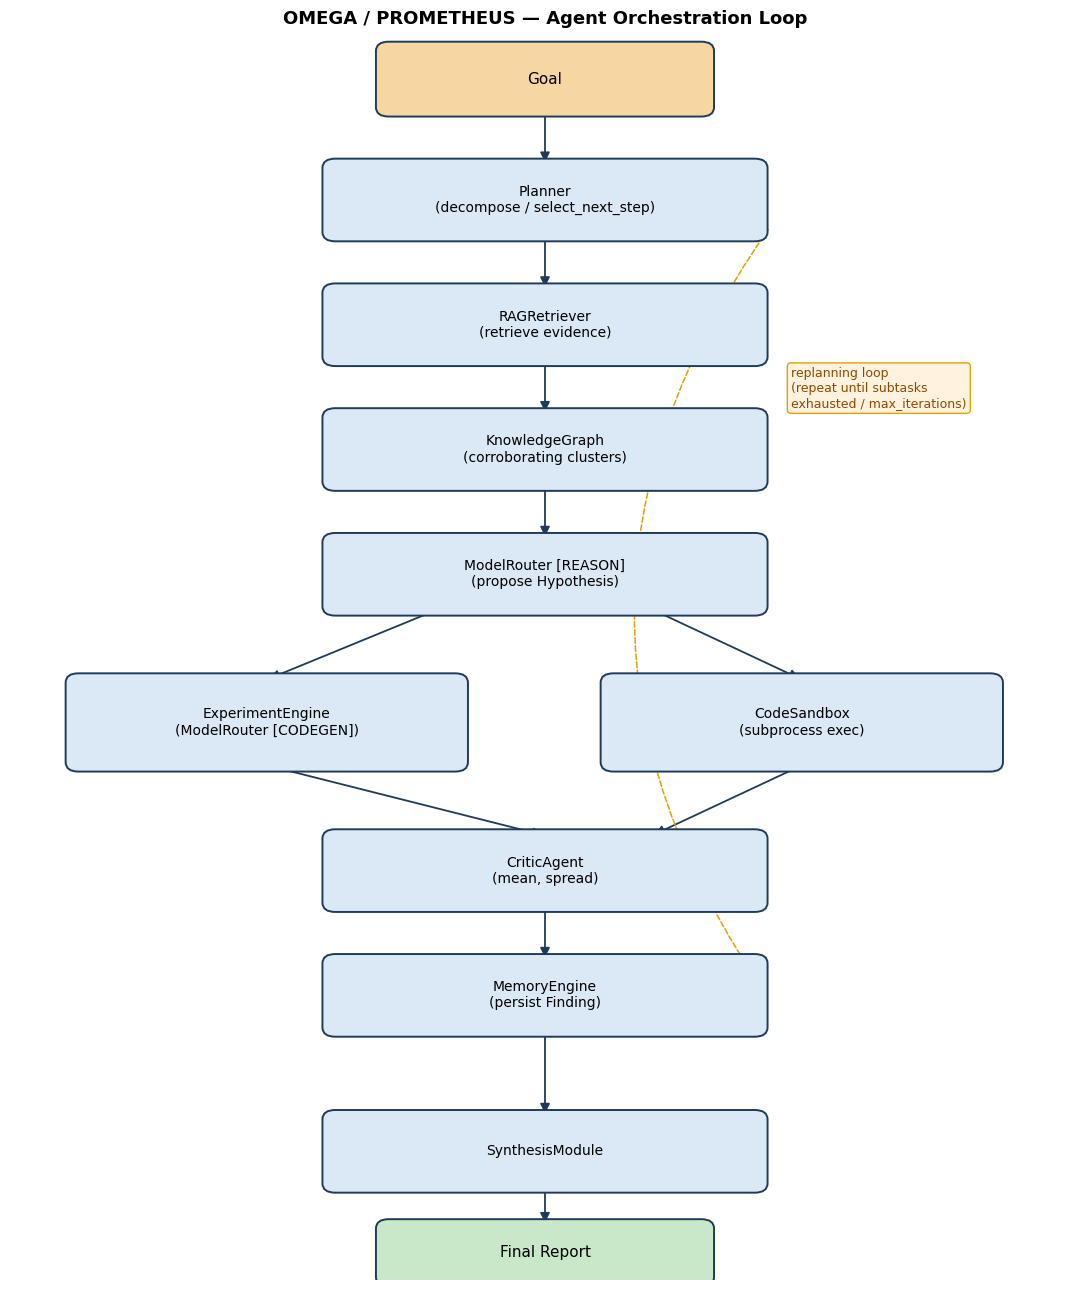

In [19]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(11, 13))
ax.set_xlim(0, 10)
ax.set_ylim(0, 16)
ax.axis("off")

def box(xy, w, h, text, color="#dbe9f6", fontsize=10):
    x, y = xy
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.08,rounding_size=0.12",
        linewidth=1.4, edgecolor="#1f3b57", facecolor=color, zorder=2,
    )
    ax.add_patch(patch)
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center",
            fontsize=fontsize, wrap=True, zorder=3)
    return (x + w / 2, y, x + w / 2, y + h)

def arrow(p_from, p_to, label=""):
    ax.add_patch(FancyArrowPatch(
        p_from, p_to, arrowstyle="-|>", mutation_scale=14,
        linewidth=1.3, color="#1f3b57", zorder=1,
    ))
    if label:
        mx, my = (p_from[0] + p_to[0]) / 2, (p_from[1] + p_to[1]) / 2
        ax.text(mx + 0.15, my, label, fontsize=8, color="#555", style="italic")

_, goal_bottom, _, goal_top = box((3.5, 15), 3, 0.8, "Goal", color="#f6d6a1", fontsize=11)
_, plan_bottom, _, plan_top = box((3, 13.4), 4, 0.9, "Planner\n(decompose / select_next_step)")
_, rag_bottom, _, rag_top = box((3, 11.8), 4, 0.9, "RAGRetriever\n(retrieve evidence)")
_, kg_bottom, _, kg_top = box((3, 10.2), 4, 0.9, "KnowledgeGraph\n(corroborating clusters)")
_, hyp_bottom, _, hyp_top = box((3, 8.6), 4, 0.9, "ModelRouter [REASON]\n(propose Hypothesis)")
_, exp_bottom, _, exp_top = box((0.6, 6.6), 3.6, 1.1, "ExperimentEngine\n(ModelRouter [CODEGEN])")
_, sbx_bottom, _, sbx_top = box((5.6, 6.6), 3.6, 1.1, "CodeSandbox\n(subprocess exec)")
_, crit_bottom, _, crit_top = box((3, 4.8), 4, 0.9, "CriticAgent\n(mean, spread)")
_, mem_bottom, _, mem_top = box((3, 3.2), 4, 0.9, "MemoryEngine\n(persist Finding)")
_, syn_bottom, _, syn_top = box((3, 1.2), 4, 0.9, "SynthesisModule")
_, rep_bottom, _, rep_top = box((3.5, 0.0), 3, 0.7, "Final Report", color="#c9e8c9", fontsize=11)

arrow((5, goal_bottom), (5, plan_top))
arrow((5, plan_bottom), (5, rag_top))
arrow((5, rag_bottom), (5, kg_top))
arrow((5, kg_bottom), (5, hyp_top))
arrow((4, hyp_bottom), (2.4, exp_top))
arrow((6, hyp_bottom), (7.4, sbx_top))
arrow((7.4, exp_bottom + 0.55), (5.6, exp_bottom + 0.55))
arrow((2.4, exp_bottom), (5, crit_top))
arrow((7.4, sbx_bottom), (6, crit_top))
arrow((5, crit_bottom), (5, mem_top))
arrow((5, mem_bottom), (5, syn_top))
arrow((5, syn_bottom), (5, rep_top))

ax.annotate("replanning loop\n(repeat until subtasks\nexhausted / max_iterations)",
            xy=(7.3, 11.2), fontsize=9, color="#8a4b00", ha="left",
            bbox=dict(boxstyle="round", fc="#fff3e0", ec="#e0a200"))
ax.add_patch(FancyArrowPatch((7.1, 13.5), (7.1, 3.6), connectionstyle="arc3,rad=0.35",
                              arrowstyle="-|>", mutation_scale=14, linewidth=1.1,
                              color="#e0a200", linestyle="--", zorder=1))

ax.set_title("OMEGA / PROMETHEUS — Agent Orchestration Loop", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


## Knowledge Graph From This Run

The actual evidence-relatedness graph built during the run above — nodes are retrieved evidence chunks, edges connect chunks whose embeddings cleared the similarity threshold (the same `build_edges` pattern SENTINEL used for spatial proximity between agents).

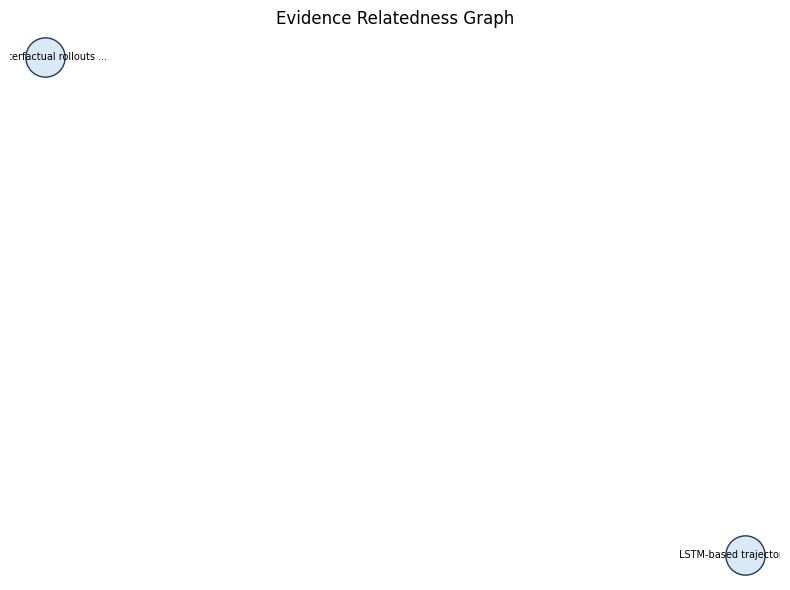

In [20]:
g = agent.knowledge_graph.graph
plt.figure(figsize=(8, 6))
if g.number_of_nodes() == 0:
    plt.text(0.5, 0.5, "No evidence chunks were ingested in this run.",
             ha="center", va="center")
    plt.axis("off")
else:
    pos = nx.spring_layout(g, seed=42)
    weights = [g[u][v]["weight"] * 3 for u, v in g.edges()]
    nx.draw_networkx_nodes(g, pos, node_color="#dbe9f6", edgecolors="#1f3b57", node_size=800)
    nx.draw_networkx_edges(g, pos, width=weights if weights else 1, edge_color="#1f3b57", alpha=0.6)
    labels = {n: (g.nodes[n]["text"][:24] + "...") for n in g.nodes()}
    nx.draw_networkx_labels(g, pos, labels, font_size=7)
    plt.title("Evidence Relatedness Graph")
    plt.axis("off")
plt.tight_layout()
plt.show()
